# Inertial sensor synchronization analysis (smartphone stack)

**Experiment.** A stack of smartphones was taped together and subjected to a
sequence of movements on a table (drag right→left, left→right, lift vertically,
move horizontally), while a stopwatch was triggered in the terminal and a video
was recorded. The goal is to analyze the **synchronization between the
devices** and between them and the **video device**.

**Data.** For each device there are three sensors exported by the HIAAC App
(`Accelerometer`, `LinearAccelerometer` and `Gyroscope`), at ~10 Hz, covering ~13 min.
Each row carries a **`VideoTimelapse`** column (in milliseconds), a time base
**common to all devices**, derived from the server clock and already aligned to
the video start.

In [1]:
import os, glob
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({'figure.figsize': (13, 4), 'axes.grid': True,
                     'grid.alpha': 0.3, 'figure.dpi': 110})

# CSV path
CANDIDATES = ['./sync_experiments/post/sync [all] [001]',
              '.', './data', '/mnt/user-data/uploads',
              os.path.expanduser('~/Downloads')]
DATA_DIR = next((c for c in CANDIDATES
                 if os.path.exists(os.path.join(c, 'Accelerometer_Annotator.csv'))), '.')
print('DATA_DIR =', os.path.abspath(DATA_DIR))

DEVICES = ['Annotator', 'Right_Pocket', 'Left_Pocket', 'Right_Hand', 'Crossbody_Bag']
SENSORS = ['Accelerometer', 'LinearAccelerometer', 'Gyroscope']
REF_DEVICE = 'Right_Pocket'          # reference device for the comparisons
COLORS = dict(zip(DEVICES, plt.cm.tab10.colors))

DATA_DIR = /home/gustavo-luz/code/mascaramento/git_temp_tests/HIAAC-Toolkit-temp/validation/synchronization/sync/sync_experiments/post/sync [all] [001]


## 1. Loading and cleaning

Each CSV has the header:
`VideoTimelapse, Experiment Name, Power Consumption (mAh), Sensor Frequency (Hz),
Timestamp Server, Timestamp Local, Value 1, Value 2, Value 3, Data Status, <app>, <model>`.

The columns were renamed and `VideoTimelapse` converted to seconds (`t`). The
`INVALID` rows were flagged and the **magnitude** computed \(\lVert v\rVert=\sqrt{v_1^2+v_2^2+v_3^2}\).

In [2]:
COLS = ['VideoTimelapse','ExpName','Power_mAh','Freq_Hz','TS_server','TS_local',
        'v1','v2','v3','Status','app','device_model']

def load_csv(sensor, device):

    path = os.path.join(DATA_DIR, f'{sensor}_{device.replace("_", " ")}.csv')
    df = pd.read_csv(path, header=0, names=COLS)
    df['t']   = df['VideoTimelapse'] / 1000.0          # seconds (video axis)
    df['mag'] = np.sqrt(df.v1**2 + df.v2**2 + df.v3**2)
    df['valid'] = df['Status'].str.strip().eq('VALID')
    return df

# data[sensor][device] -> DataFrame
data = {s: {d: load_csv(s, d) for d in DEVICES} for s in SENSORS}

# Summary
rows = []
for s in SENSORS:
    for d in DEVICES:
        df = data[s][d]
        rows.append([s, d, df.device_model.iloc[0], len(df),
                     int((~df.valid).sum()),
                     round(df.t.min(),1), round(df.t.max(),1)])
summary = pd.DataFrame(rows, columns=['sensor','device','model','n',
                                      'invalid','t_start(s)','t_end(s)'])
summary

,sensor,device,model,n,invalid,t_start(s),t_end(s)
0,Accelerometer,Annotator,NaN,7990,1,0.3,799.2
1,Accelerometer,Right_Pocket,NaN,7993,0,0.0,799.2
2,Accelerometer,Left_Pocket,NaN,7992,0,0.1,799.2
3,Accelerometer,Right_Hand,NaN,7992,0,0.1,799.2
4,Accelerometer,Crossbody_Bag,NaN,7993,0,0.0,799.2
5,LinearAccelerometer,Annotator,NaN,7990,2,0.3,799.2
6,LinearAccelerometer,Right_Pocket,NaN,7993,0,0.0,799.2
7,LinearAccelerometer,Left_Pocket,NaN,7992,0,0.1,799.2
8,LinearAccelerometer,Right_Hand,NaN,7992,0,0.1,799.2
9,LinearAccelerometer,Crossbody_Bag,NaN,7993,0,0.0,799.2


## 2. Time base and sampling quality

Each device's `VideoTimelapse` is `Timestamp Server − offset`. This **reference
offset is identical** across all devices and sensors, ensuring that they all
share the same timeline and that the synchronization can be measured directly.
The sampling step (expected ~100 ms) and any gaps in the series were checked.

In [3]:
ref_offsets = {}
for s in SENSORS:
    for d in DEVICES:
        df = data[s][d]
        ref_offsets[(s, d)] = int((df.TS_server - df.VideoTimelapse).iloc[1])
print('Distinct reference offsets:', set(ref_offsets.values()),
      '  -> common time base:', len(set(ref_offsets.values())) == 1)

# Sampling and gap statistics per device (LinearAccelerometer)
grows = []
for d in DEVICES:
    dt = np.diff(data['LinearAccelerometer'][d].t.values)      # s
    grows.append([d, round(np.median(dt)*1000,1), round(dt.max()*1000,1),
                  int((dt > 0.25).sum())])   # gaps > 250 ms
pd.DataFrame(grows, columns=['device','dt_median(ms)','max_gap(ms)','gaps>250ms'])

Distinct reference offsets: {1782415607558}   -> common time base: True


,device,dt_median(ms),max_gap(ms),gaps>250ms
0,Annotator,100.0,100.0,0
1,Right_Pocket,100.0,100.0,0
2,Left_Pocket,100.0,100.0,0
3,Right_Hand,100.0,100.0,0
4,Crossbody_Bag,100.0,100.0,0


## 3. Activity windows (annotated from the video)

The instants below were read directly from the video, in the format
**`min:sec:hundredths`** (e.g. `01:15:22` = 1 min 15.22 s). Since `VideoTimelapse`
is already on the same scale as the video, these instants are used directly as the
start/end of each activity window.

These windows become the **focus of all the following analyses** (peak detection,
overlay, cross-correlation and jitter). The automatic threshold detection
(section 4) is kept only as a visual cross-check.

In [4]:
def mmsscs_to_s(ts):
    """Convert 'MM:SS:CS' (minutes:seconds:hundredths) to seconds."""
    mm, ss, cs = (int(x) for x in ts.split(':'))
    return mm*60 + ss + cs/100.0

# (movement, repetition, start, end)
ANNOTATIONS = [
    ('vertical',                    'start',        '01:15:22', '01:17:25'),
    ('horizontal',                  'start',        '01:17:25', '01:19:25'),
    ('horizontal_position_change',  'start',        '01:21:01', '01:23:27'),
    ('horizontal',                  'repetition 1', '01:32:03', '01:39:08'),
    ('horizontal',                  'repetition 2', '10:30:18', '10:33:01'),
    ('vertical',                    'repetition',   '10:33:07', '10:39:19'),
    ('table',                       'repetition',   '11:25:26', '11:37:19'),
]

rows = []
ACTIVITY_WINDOWS = {}
for label, rep, ini, fim in ANNOTATIONS:
    t0, t1 = mmsscs_to_s(ini), mmsscs_to_s(fim)
    ACTIVITY_WINDOWS.setdefault(label, []).append((t0, t1))
    rows.append([label, rep, ini, fim, round(t0, 2), round(t1, 2), round(t1 - t0, 2)])

annotations_tbl = pd.DataFrame(rows, columns=['movement', 'repetition', 'start(video)',
                                              'end(video)', 't0(s)', 't1(s)', 'duration(s)']
                               ).sort_values('t0(s)').reset_index(drop=True)

# windows "flattened" in chronological order
windows = list(zip(annotations_tbl['t0(s)'], annotations_tbl['t1(s)']))
print(f'{len(windows)} manually annotated activity windows:')
annotations_tbl

7 manually annotated activity windows:


,movement,repetition,start(video),end(video),t0(s),t1(s),duration(s)
0,vertical,start,01:15:22,01:17:25,75.22,77.25,2.03
1,horizontal,start,01:17:25,01:19:25,77.25,79.25,2.00
2,horizontal_position_change,start,01:21:01,01:23:27,81.01,83.27,2.26
3,horizontal,repetition 1,01:32:03,01:39:08,92.03,99.08,7.05
4,horizontal,repetition 2,10:30:18,10:33:01,630.18,633.01,2.83
5,vertical,repetition,10:33:07,10:39:19,633.07,639.19,6.12
6,table,repetition,11:25:26,11:37:19,685.26,697.19,11.93


## 4. Timeline overview

We plot the **linear acceleration** magnitude (gravity removed) of the reference
device over the whole recording. The colored bands mark the **annotated activity
windows** (section 3); the automatic threshold detection below (`auto_windows`)
serves only as a cross-check.

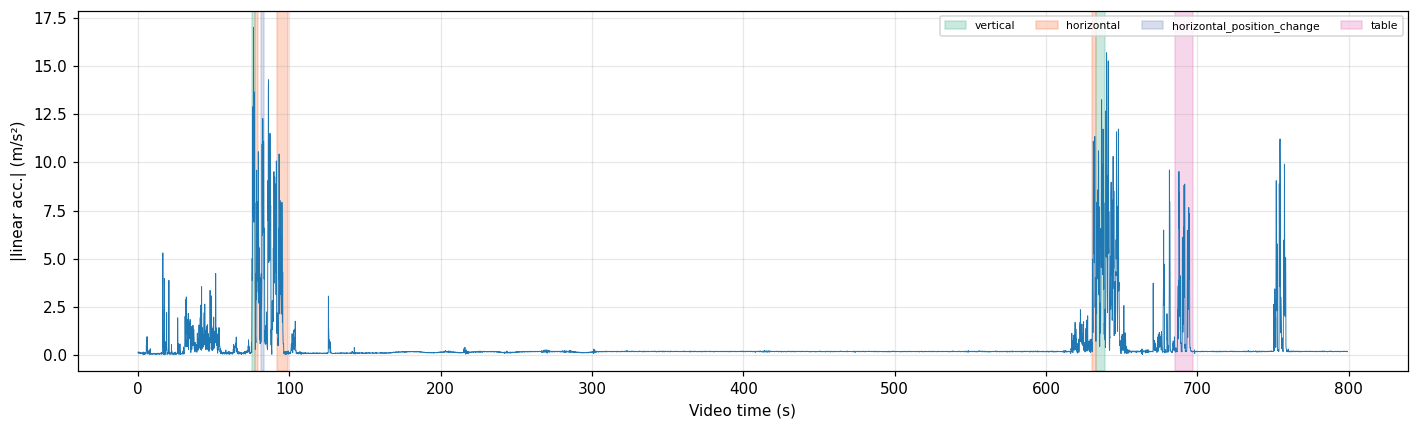

Figure saved: fig_overview.png
Automatically detected active windows (cross-check only):
     16.2 ..    20.4   (  4.2 s)
     31.0 ..    53.7   ( 22.7 s)
     75.2 ..    95.7   ( 20.5 s)
    101.8 ..   104.0   (  2.2 s)
    617.0 ..   652.5   ( 35.5 s)
    670.8 ..   694.9   ( 24.1 s)
    750.5 ..   758.4   (  7.9 s)


In [5]:
ref = data['LinearAccelerometer'][REF_DEVICE]
plt.figure()
plt.plot(ref.t, ref.mag, lw=0.6, color='tab:blue')
WINDOW_COLORS = dict(zip(ACTIVITY_WINDOWS.keys(), plt.cm.Set2.colors))
for label, ws in ACTIVITY_WINDOWS.items():
    for t0, t1 in ws:
        plt.axvspan(t0, t1, color=WINDOW_COLORS[label], alpha=0.35,
                    label=label if (t0, t1) == ws[0] else None)
plt.legend(ncol=len(ACTIVITY_WINDOWS), fontsize=7, loc='upper right')
plt.xlabel('Video time (s)'); plt.ylabel('|linear acc.| (m/s²)')
plt.tight_layout()
plt.savefig('fig_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: fig_overview.png')

# Automatic threshold detection (cross-check of the annotated windows)
THR_ACTIVE = 0.8      # m/s²
MERGE_GAP  = 4.0      # s: merges blocks separated by less than this
MIN_DUR    = 1.0      # s: discards blocks that are too short

act = ref[ref.mag > THR_ACTIVE].t.values
auto_windows = []
if len(act):
    start = prev = act[0]
    for x in act[1:]:
        if x - prev > MERGE_GAP:
            auto_windows.append((start, prev)); start = x
        prev = x
    auto_windows.append((start, prev))
auto_windows = [(a, b) for a, b in auto_windows if b - a >= MIN_DUR]
print('Automatically detected active windows (cross-check only):')
for a, b in auto_windows:
    print(f'  {a:7.1f} .. {b:7.1f}   ({b-a:5.1f} s)')

# Gyroscope

## 5. Movement event detection (within the annotated windows)

We look for **peaks** in the linear acceleration magnitude, restricted to the
**annotated activity windows** (section 3) — each window is processed separately
so that samples from non-contiguous windows are not mixed in the peak search.
Adjust `PEAK_HEIGHT` and `PEAK_DIST_S` to the intensity and spacing of your
movements.

15 peaks detected on device Right_Pocket (restricted to the 7 annotated windows).


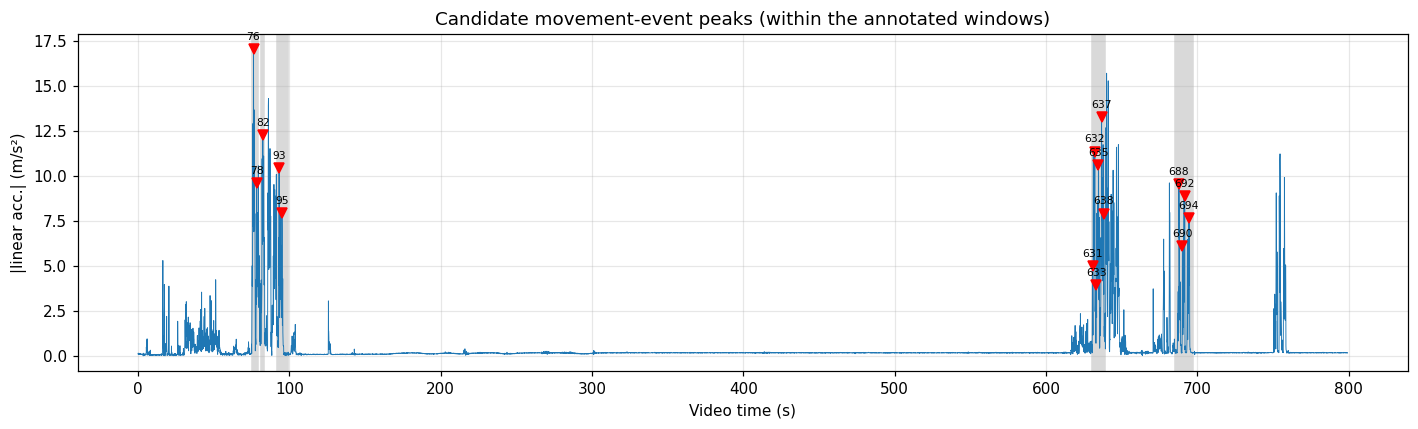

,event,t_video(s),peak |lin.acc.| (m/s²)
0,1,76.3,17.02
1,2,78.4,9.60
2,3,82.4,12.28
3,4,93.2,10.44
4,5,95.1,7.93
5,6,630.7,4.98
6,7,632.2,11.35
7,8,633.2,3.96
8,9,634.6,10.60
9,10,636.7,13.26


In [6]:
PEAK_HEIGHT = 2.0     # m/s²  (minimum peak height)
PEAK_DIST_S = 1.5     # s      (minimum separation between peaks)

t = ref.t.values
mag = ref.mag.values
fs_est = 1.0 / np.median(np.diff(t))          # ~10 Hz

def find_peaks_in_windows(t, mag, wins, height, dist_s, fs):
    idx = []
    for t0, t1 in wins:
        m = (t >= t0) & (t <= t1)
        loc = np.where(m)[0]
        if len(loc) == 0:
            continue
        pk, _ = find_peaks(mag[loc], height=height, distance=max(1, int(dist_s * fs)))
        idx.extend(loc[pk])
    return np.array(sorted(set(idx)))

peaks = find_peaks_in_windows(t, mag, windows, PEAK_HEIGHT, PEAK_DIST_S, fs_est)

events = pd.DataFrame({
    'event': np.arange(1, len(peaks)+1),
    't_video(s)': np.round(t[peaks], 2),
    'peak |lin.acc.| (m/s²)': np.round(mag[peaks], 2),
})
print(f'{len(peaks)} peaks detected on device {REF_DEVICE} '
      f'(restricted to the {len(windows)} annotated windows).')

plt.figure()
plt.plot(t, mag, lw=0.6, color='tab:blue')
for t0, t1 in windows:
    plt.axvspan(t0, t1, color='0.85', zorder=0)
plt.plot(t[peaks], mag[peaks], 'rv', ms=6)
for p in peaks:
    plt.annotate(f'{t[p]:.0f}', (t[p], mag[p]), textcoords='offset points',
                 xytext=(0,6), fontsize=7, ha='center')
plt.xlabel('Video time (s)'); plt.ylabel('|linear acc.| (m/s²)')
plt.title('Candidate movement-event peaks (within the annotated windows)')
plt.tight_layout(); plt.show()
events

## 6. Characterizing each movement (per-axis direction)

Dragging on the table dominates one horizontal axis; lifting vertically dominates
the vertical axis; rotation (gyroscope) helps tell "lift/turn" apart from
"translate". Use `plot_window(...)` to zoom into any segment. Below we show, for
each **annotated movement type**, the first occurrence in the corresponding
window.

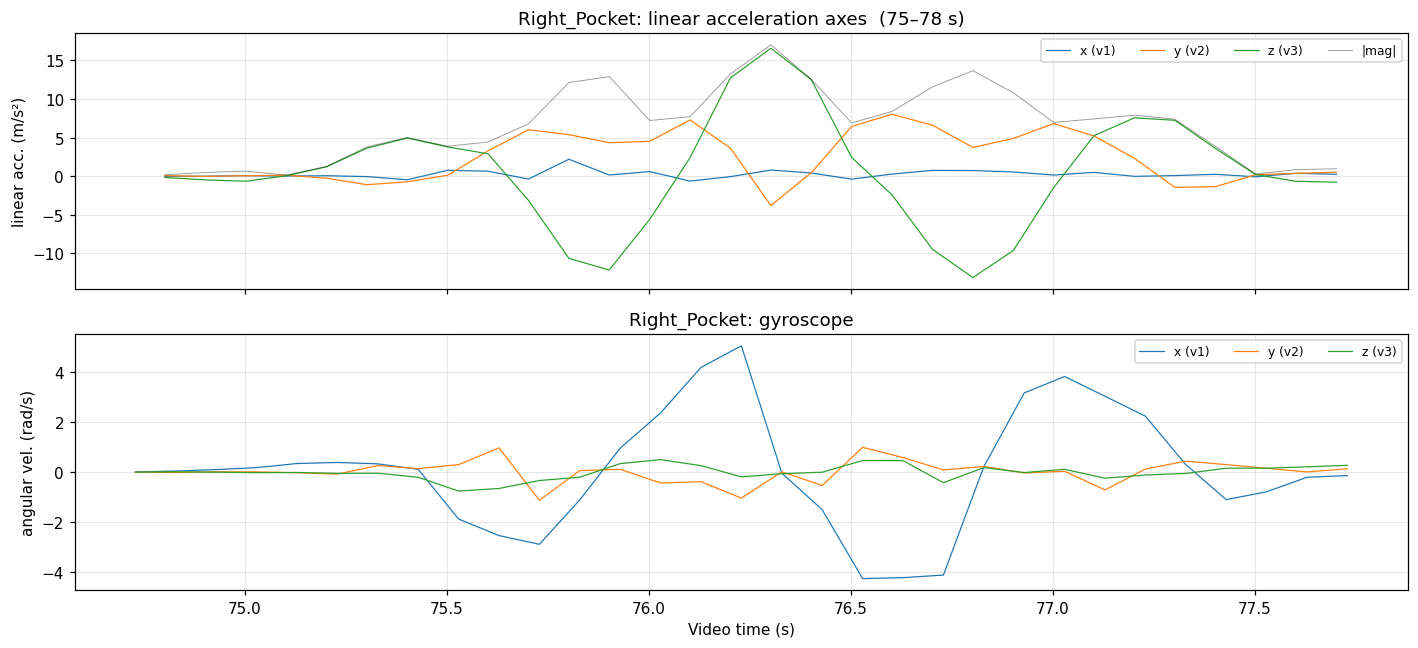

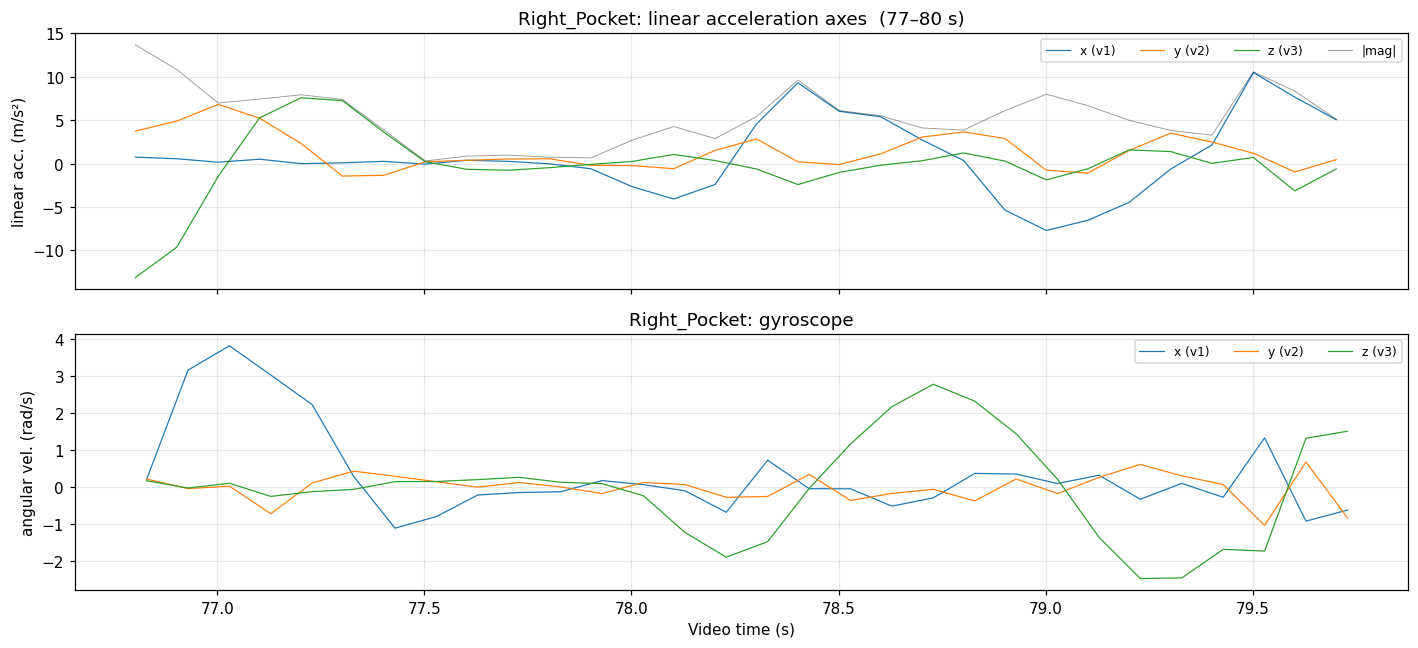

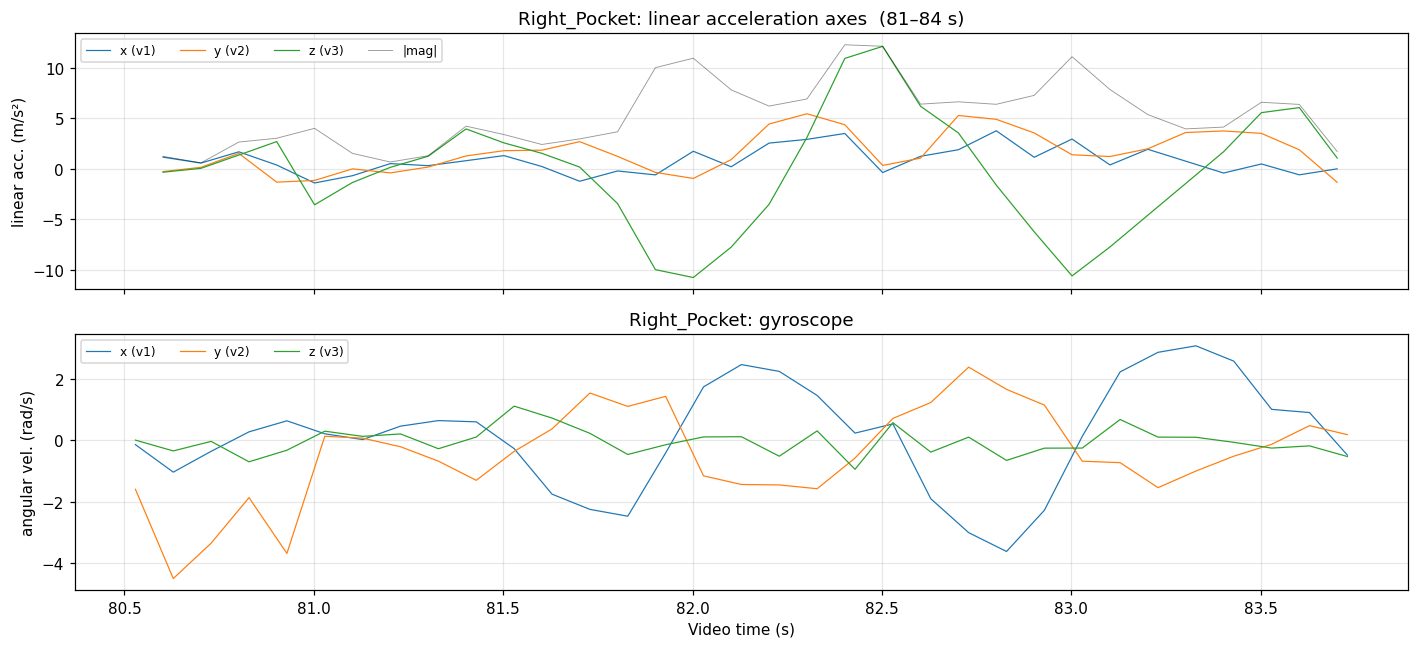

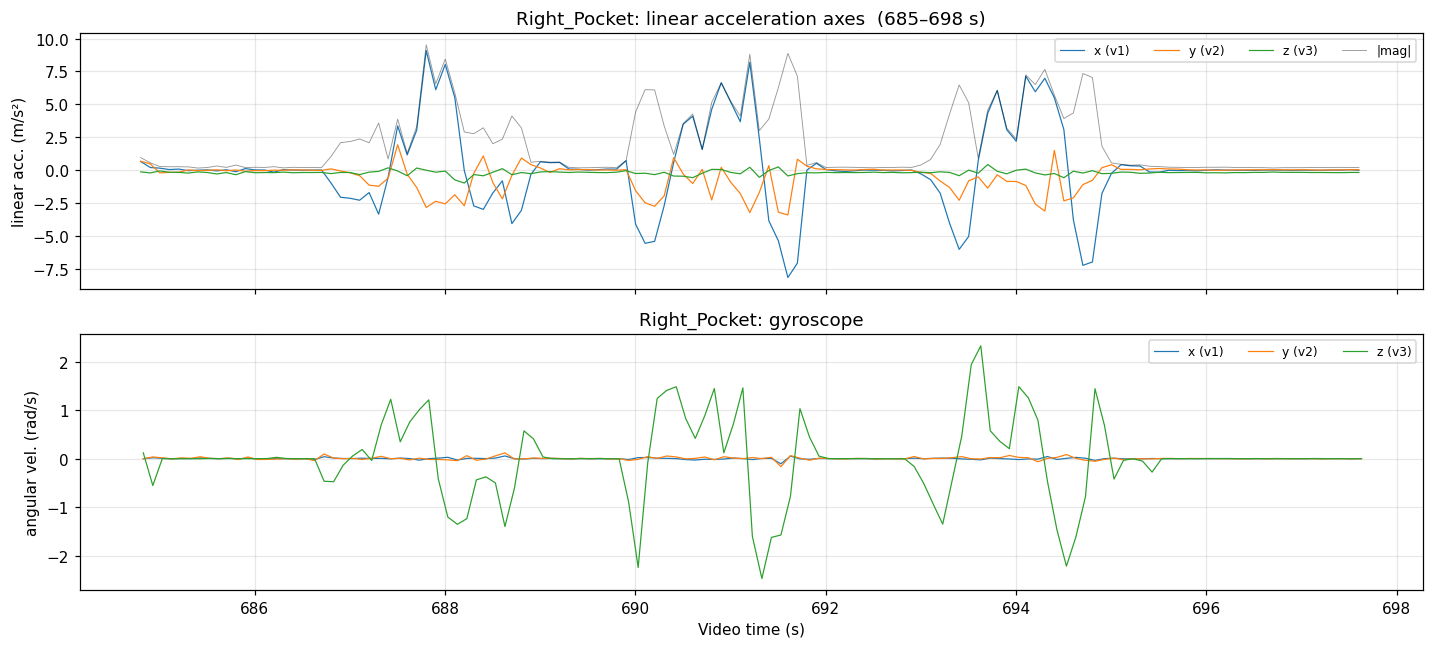

In [7]:
def plot_window(t0, t1, device=REF_DEVICE, mark_video=True):
    la = data['LinearAccelerometer'][device]
    gy = data['Gyroscope'][device]
    m_la = (la.t >= t0) & (la.t <= t1)
    m_gy = (gy.t >= t0) & (gy.t <= t1)

    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    for c, lbl in zip(['v1','v2','v3'], ['x (v1)','y (v2)','z (v3)']):
        ax[0].plot(la.t[m_la], la[c][m_la], lw=0.8, label=lbl)
    ax[0].plot(la.t[m_la], la.mag[m_la], 'k', lw=0.6, alpha=0.4, label='|mag|')
    ax[0].set_ylabel('linear acc. (m/s²)'); ax[0].legend(ncol=4, fontsize=8)
    ax[0].set_title(f'{device}: linear acceleration axes  ({t0:.0f}–{t1:.0f} s)')

    for c, lbl in zip(['v1','v2','v3'], ['x (v1)','y (v2)','z (v3)']):
        ax[1].plot(gy.t[m_gy], gy[c][m_gy], lw=0.8, label=lbl)
    ax[1].set_ylabel('angular vel. (rad/s)'); ax[1].set_xlabel('Video time (s)')
    ax[1].legend(ncol=3, fontsize=8); ax[1].set_title(f'{device}: gyroscope')

    if mark_video:
        for lab, tv in VIDEO_EVENTS:
            for a in ax:
                a.axvline(tv, color='red', ls='--', lw=0.8, alpha=0.7)
            ax[0].annotate(lab, (tv, ax[0].get_ylim()[1]), color='red',
                           fontsize=7, rotation=90, va='top')
    plt.tight_layout(); plt.show()

VIDEO_EVENTS = []   # filled in section 10 (synchronization with the video)

for label, ws in ACTIVITY_WINDOWS.items():
    t0, t1 = ws[0]
    plot_window(t0 - 0.5, t1 + 0.5)

## 7. Device overlay (visual synchronization check)

Since the phones are glued together, they should all record **the same movement
at the same time**. Overlaying the magnitudes in each annotated activity window,
the curves should coincide almost perfectly — any visible shift would be
desynchronization.

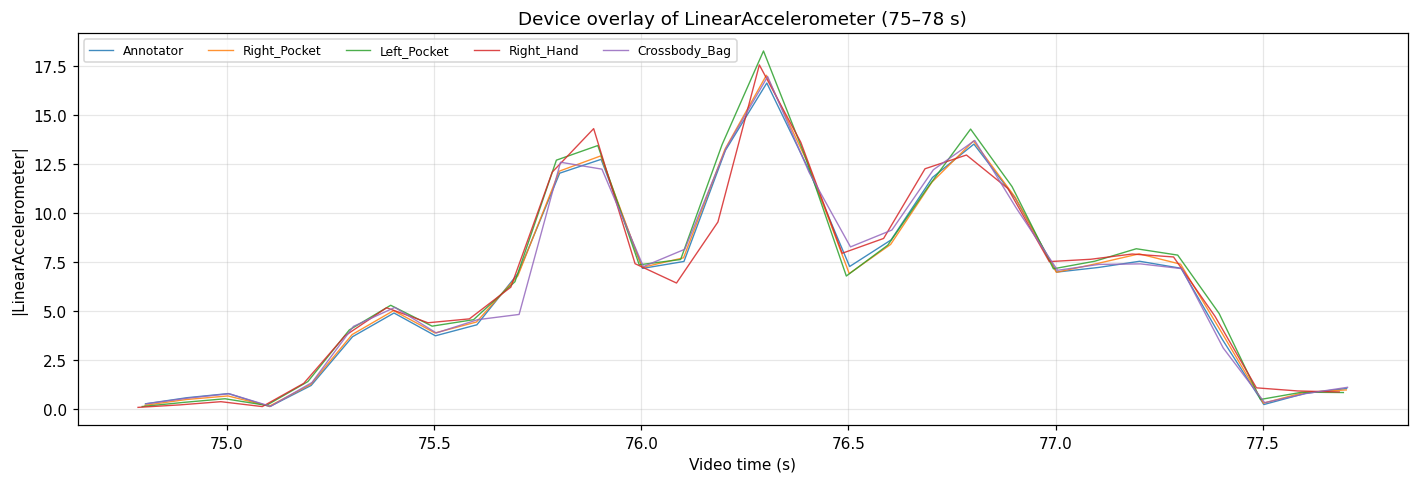

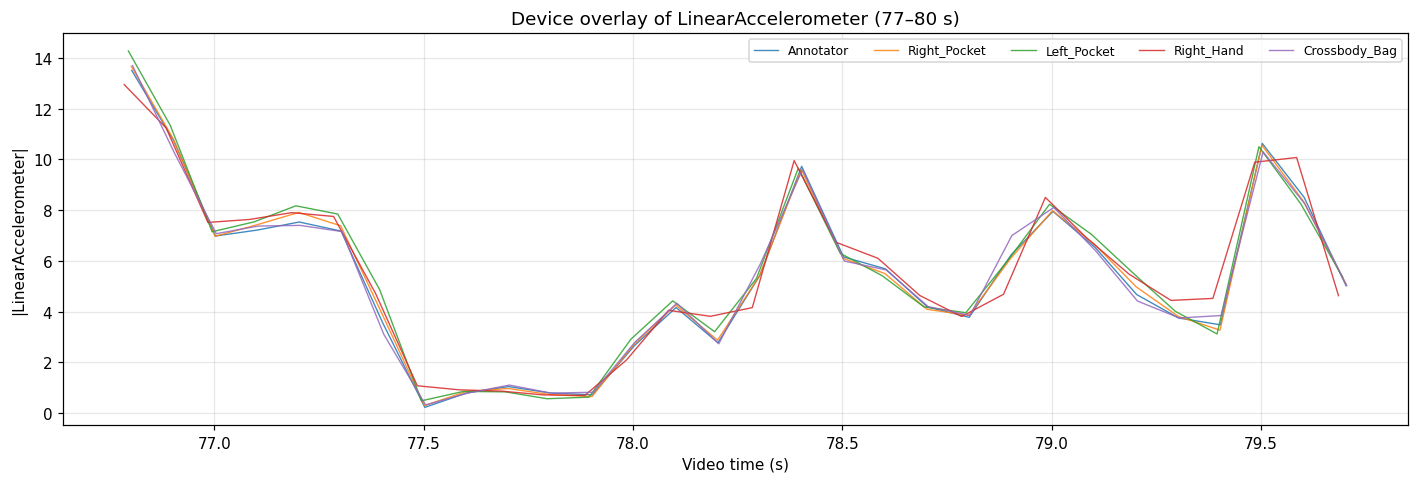

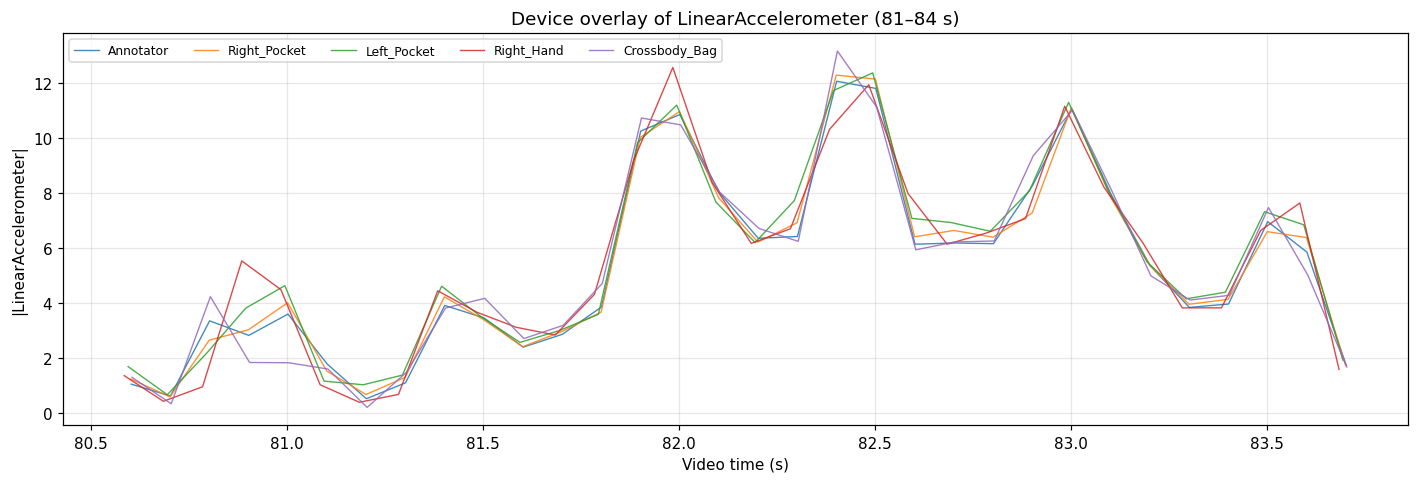

Figure saved: fig_overlay_table.png


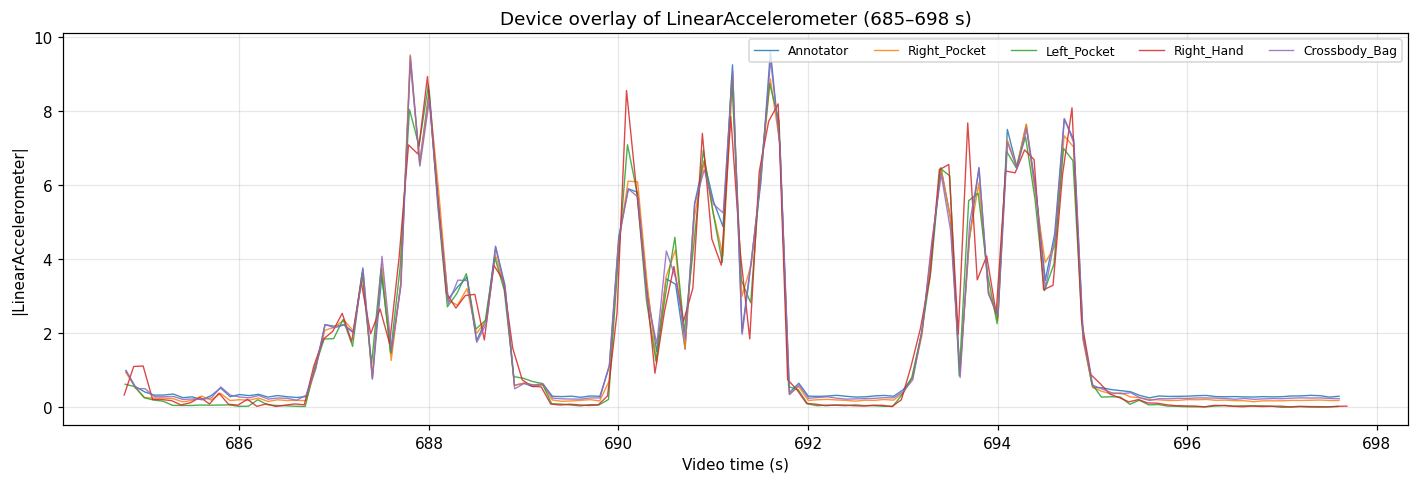

In [8]:
def overlay(t0, t1, sensor='LinearAccelerometer', savepath=None):
    plt.figure(figsize=(13, 4.5))
    for d in DEVICES:
        df = data[sensor][d]
        m = (df.t >= t0) & (df.t <= t1)
        plt.plot(df.t[m], df.mag[m], lw=0.9, label=d, color=COLORS[d], alpha=0.85)
    plt.xlabel('Video time (s)'); plt.ylabel(f'|{sensor}|')
    plt.title(f'Device overlay of {sensor} ({t0:.0f}–{t1:.0f} s)')
    plt.legend(ncol=5, fontsize=8); plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=150, bbox_inches='tight')
        print(f'Figure saved: {savepath}')
    plt.show()

for label, ws in ACTIVITY_WINDOWS.items():
    t0, t1 = ws[0]
    savepath = 'fig_overlay_table.png' if label == 'table' else None
    overlay(t0 - 0.5, t1 + 0.5, savepath=savepath)

## 8. Inter-device synchronization (quantitative, per window)

We resample each signal onto a common high-resolution time grid and compute the
**cross-correlation** against the reference device, **within each annotated
activity window** (instead of the whole recording) — this prevents the long idle
stretches between blocks from dominating the correlation. The *lag* that maximizes
the correlation is the estimated offset; the Pearson coefficient measures how much
the signals agree. With the glued stack we expect lag ≈ 0 and high correlation
**in every window**; the window-to-window variation of the lag over time is the
jitter analyzed in section 9.

In [9]:
GRID_HZ = 100.0                       # lag resolution = 10 ms
SENSOR_SYNC = 'LinearAccelerometer'

def resample_window(sensor, device, t0, t1, fs=GRID_HZ):
    df = data[sensor][device]
    grid = np.arange(t0, t1, 1.0/fs)
    return grid, np.interp(grid, df.t.values, df.mag.values)

def best_lag(a, b, fs=GRID_HZ):
    a = a - a.mean(); b = b - b.mean()
    xc = np.correlate(a, b, 'full')
    lag = (xc.argmax() - (len(a) - 1)) / fs * 1000.0    # ms
    return lag

rows = []
for _, row in annotations_tbl.iterrows():
    t0, t1 = row['t0(s)'], row['t1(s)']
    _, ref_sig = resample_window(SENSOR_SYNC, REF_DEVICE, t0, t1)
    for d in DEVICES:
        _, sig = resample_window(SENSOR_SYNC, d, t0, t1)
        lag = best_lag(ref_sig, sig)
        r = np.corrcoef(ref_sig, sig)[0, 1]
        rows.append([row['movement'], row['repetition'], t0, t1, d,
                     round(lag, 1), round(r, 3)])

LAG_COL = f'lag_vs_{REF_DEVICE}(ms)'
sync_win_tbl = pd.DataFrame(rows, columns=['movement', 'repetition', 't0(s)', 't1(s)',
                                           'device', LAG_COL, 'r'])
print(f'Synchronization via {SENSOR_SYNC}, one row per annotated window x device '
      f'(lag resolution = {1000/GRID_HZ:.0f} ms):')
sync_win_tbl

Synchronization via LinearAccelerometer, one row per annotated window x device (lag resolution = 10 ms):


,movement,repetition,t0(s),t1(s),device,lag_vs_Right_Pocket(ms),r
0,vertical,start,75.22,77.25,Annotator,0.0,0.999
1,vertical,start,75.22,77.25,Right_Pocket,0.0,1.000
2,vertical,start,75.22,77.25,Left_Pocket,0.0,0.997
3,vertical,start,75.22,77.25,Right_Hand,0.0,0.979
4,vertical,start,75.22,77.25,Crossbody_Bag,0.0,0.989
5,horizontal,start,77.25,79.25,Annotator,0.0,0.999
6,horizontal,start,77.25,79.25,Right_Pocket,0.0,1.000
7,horizontal,start,77.25,79.25,Left_Pocket,0.0,0.997
8,horizontal,start,77.25,79.25,Right_Hand,0.0,0.992
9,horizontal,start,77.25,79.25,Crossbody_Bag,0.0,0.995


In [10]:
sync_tbl = (sync_win_tbl.groupby('device')[LAG_COL]
            .agg(['mean', 'std', 'min', 'max']).round(2)
            .rename(columns={'mean': 'lag_mean(ms)', 'std': 'lag_jitter_std(ms)',
                             'min': 'lag_min(ms)', 'max': 'lag_max(ms)'})
            .reindex(DEVICES))
print(f'Per-device summary, aggregating the {len(annotations_tbl)} annotated windows:')
display(sync_tbl)

# Pairwise lag matrix (ms), mean and standard deviation across the annotated windows
mats = []
for _, row in annotations_tbl.iterrows():
    t0, t1 = row['t0(s)'], row['t1(s)']
    sigs = {d: resample_window(SENSOR_SYNC, d, t0, t1)[1] for d in DEVICES}
    Mw = pd.DataFrame(index=DEVICES, columns=DEVICES, dtype=float)
    for i in DEVICES:
        for j in DEVICES:
            Mw.loc[i, j] = best_lag(sigs[i], sigs[j])
    mats.append(Mw)

M = sum(mats) / len(mats)
M_std = pd.concat(mats).groupby(level=0).std().reindex(DEVICES)[DEVICES]
print('Mean pairwise lag matrix (ms) across the annotated windows '
      '— row delayed relative to column:')
display(M.round(1))
print('Standard deviation of the pairwise lag across the windows (jitter, ms):')
M_std.round(2)

Per-device summary, aggregating the 7 annotated windows:


,lag_mean(ms),lag_jitter_std(ms),lag_min(ms),lag_max(ms)
device,,,,
Annotator,0.00,0.00,0.0,0.0
Right_Pocket,0.00,0.00,0.0,0.0
Left_Pocket,0.00,0.00,0.0,0.0
Right_Hand,0.00,0.00,0.0,0.0
Crossbody_Bag,1.43,3.78,0.0,10.0


Mean pairwise lag matrix (ms) across the annotated windows — row delayed relative to column:


,Annotator,Right_Pocket,Left_Pocket,Right_Hand,Crossbody_Bag
Annotator,0.0,0.0,0.0,0.0,0.0
Right_Pocket,0.0,0.0,0.0,0.0,1.4
Left_Pocket,0.0,0.0,0.0,0.0,0.0
Right_Hand,0.0,0.0,0.0,0.0,1.4
Crossbody_Bag,0.0,-1.4,0.0,-1.4,0.0


Standard deviation of the pairwise lag across the windows (jitter, ms):


,Annotator,Right_Pocket,Left_Pocket,Right_Hand,Crossbody_Bag
Annotator,0.0,0.00,0.0,0.00,0.00
Right_Pocket,0.0,0.00,0.0,0.00,3.78
Left_Pocket,0.0,0.00,0.0,0.00,0.00
Right_Hand,0.0,0.00,0.0,0.00,3.78
Crossbody_Bag,0.0,3.78,0.0,3.78,0.00


## 9. Jitter analysis

Two possible sources of jitter:

1. **Sampling jitter (intra-device)** — variation of the interval between
   consecutive samples (`Δt`), expected ≈ 100 ms. Measured within the annotated
   activity windows.
2. **Synchronization jitter (inter-device, over time)** — how much the estimated
   offset (section 8) varies across the different windows, spread over the ~13 min
   of the recording. This captures any clock *drift* between devices that a single
   measurement, taken on one segment, would not reveal.

In [11]:
rows = []
for d in DEVICES:
    df = data['LinearAccelerometer'][d]
    dts = []
    for t0, t1 in windows:
        m = (df.t >= t0) & (df.t <= t1)
        dts.append(np.diff(df.t[m].values) * 1000.0)   # ms
    dt_all = np.concatenate(dts)
    rows.append([d, len(dt_all), round(dt_all.mean(), 4), round(dt_all.std(), 4),
                 round(dt_all.min(), 3), round(dt_all.max(), 3),
                 int((np.abs(dt_all - 100) > 20).sum())])

jitter_dt_tbl = pd.DataFrame(rows, columns=['device', 'n_samples', 'dt_mean(ms)',
                                            'dt_jitter_std(ms)', 'dt_min(ms)',
                                            'dt_max(ms)', 'dt_outside_±20ms'])
print('Sampling-interval jitter, measured within the annotated windows:')
display(jitter_dt_tbl)
print('\nThe standard deviation is on the order of 1e-11 ms (floating-point noise): '
      'the exported `VideoTimelapse` / `Timestamp Server` / `Timestamp Local` sit on a '
      'perfectly uniform 100 ms grid -- they do not reflect the real sensor capture '
      'jitter (the HIAAC App export appears to already quantize/realign the '
      'timestamps). In other words: there is no measurable sampling jitter in these '
      'files; the jitter source relevant to synchronization is the one analyzed next.')

Sampling-interval jitter, measured within the annotated windows:


,device,n_samples,dt_mean(ms),dt_jitter_std(ms),dt_min(ms),dt_max(ms),dt_outside_±20ms
0,Annotator,334,100.0,0.0,100.0,100.0,0
1,Right_Pocket,334,100.0,0.0,100.0,100.0,0
2,Left_Pocket,334,100.0,0.0,100.0,100.0,0
3,Right_Hand,336,100.0,0.0,100.0,100.0,0
4,Crossbody_Bag,334,100.0,0.0,100.0,100.0,0



The standard deviation is on the order of 1e-11 ms (floating-point noise): the exported `VideoTimelapse` / `Timestamp Server` / `Timestamp Local` sit on a perfectly uniform 100 ms grid -- they do not reflect the real sensor capture jitter (the HIAAC App export appears to already quantize/realign the timestamps). In other words: there is no measurable sampling jitter in these files; the jitter source relevant to synchronization is the one analyzed next.


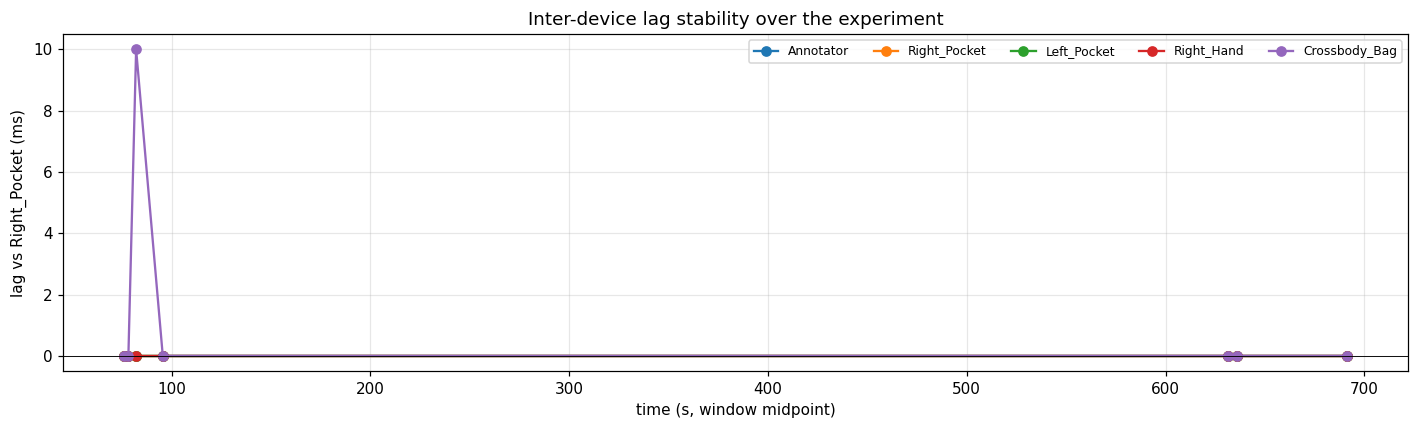

Figure saved: fig_lag_stability.png
Lag jitter (standard deviation across the 7 annotated windows, ms) per device -- the larger it is, the less stable the synchronization over time:


,lag_mean(ms),lag_jitter_std(ms),lag_min(ms),lag_max(ms)
device,,,,
Crossbody_Bag,1.43,3.78,0.0,10.0
Annotator,0.00,0.00,0.0,0.0
Right_Pocket,0.00,0.00,0.0,0.0
Left_Pocket,0.00,0.00,0.0,0.0
Right_Hand,0.00,0.00,0.0,0.0


In [12]:
plt.figure()
for d in DEVICES:
    sub = sync_win_tbl[sync_win_tbl.device == d].sort_values('t0(s)')
    tmid = (sub['t0(s)'] + sub['t1(s)']) / 2
    plt.plot(tmid, sub[LAG_COL], 'o-', label=d, color=COLORS[d])
plt.axhline(0, color='k', lw=0.6)
plt.xlabel('time (s, window midpoint)')
plt.ylabel(f'lag vs {REF_DEVICE} (ms)')
plt.title('Inter-device lag stability over the experiment')
plt.legend(ncol=5, fontsize=8); plt.tight_layout()
plt.savefig('fig_lag_stability.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: fig_lag_stability.png')

print(f'Lag jitter (standard deviation across the {len(windows)} annotated windows, ms) '
      'per device -- the larger it is, the less stable the synchronization over '
      'time:')
sync_tbl.sort_values('lag_jitter_std(ms)', ascending=False)

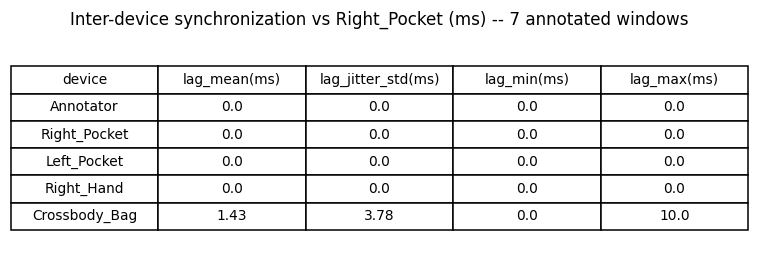

Figure saved: sync_table.png


In [13]:
# Summary table as an image, ready to paste into a slide
tbl_data = sync_tbl.reset_index()
fig, ax = plt.subplots(figsize=(7, 0.5 + 0.4*len(tbl_data)))
ax.axis('off')
tbl = ax.table(cellText=tbl_data.values, colLabels=tbl_data.columns,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.5)
ax.set_title(f'Inter-device synchronization vs {REF_DEVICE} (ms) -- '
             f'{len(annotations_tbl)} annotated windows', fontsize=11, pad=12)
plt.tight_layout()
plt.savefig('sync_table.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: sync_table.png')

**Why most lags are exactly 0 ms.** This is not a coincidence: section 2 already
showed that `TS_server − VideoTimelapse` is bit-for-bit identical across the 5
devices (`ref_offsets`), i.e. `VideoTimelapse` is born on a common time base by
construction — the cross-correlation is only confirming something guaranteed
beforehand. Moreover, `GRID_HZ = 100` makes the lag only take multiples of 10 ms;
since the real mechanical delay in a glued stack is much smaller than that, any
value below ~5 ms is rounded to `0.0`. The `r` (Pearson) close to 1 is what
guarantees this is not an "empty" zero: the signals really do have the same shape.

Below we isolate the (few) rows where the lag did not fall to zero, so it is not
hidden inside the aggregated table.

In [14]:
nonzero = sync_win_tbl[sync_win_tbl[LAG_COL] != 0]
print(f'{len(nonzero)} of {len(sync_win_tbl)} rows (window x device) with lag != 0:')
if len(nonzero):
    display(nonzero)
    # context: the other devices in the same window(s), to compare the r
    ctx = sync_win_tbl[sync_win_tbl['t0(s)'].isin(nonzero['t0(s)'])]
    print('\nContext -- all devices in the same windows (note that r drops a bit '
          'for all of them there, not only for the one with lag != 0):')
    display(ctx)
else:
    print('None -- every window converged to lag = 0 on all devices.')

1 of 35 rows (window x device) with lag != 0:


,movement,repetition,t0(s),t1(s),device,lag_vs_Right_Pocket(ms),r
14,horizontal_position_change,start,81.01,83.27,Crossbody_Bag,10.0,0.986



Context -- all devices in the same windows (note that r drops a bit for all of them there, not only for the one with lag != 0):


,movement,repetition,t0(s),t1(s),device,lag_vs_Right_Pocket(ms),r
10,horizontal_position_change,start,81.01,83.27,Annotator,0.0,0.997
11,horizontal_position_change,start,81.01,83.27,Right_Pocket,0.0,1.000
12,horizontal_position_change,start,81.01,83.27,Left_Pocket,0.0,0.996
13,horizontal_position_change,start,81.01,83.27,Right_Hand,0.0,0.987
14,horizontal_position_change,start,81.01,83.27,Crossbody_Bag,10.0,0.986


## 11. Export summaries

In [15]:
events.to_csv('detected_events.csv', index=False)
annotations_tbl.to_csv('annotated_activity_windows.csv', index=False)
sync_win_tbl.to_csv('synchronization_per_window.csv', index=False)
sync_tbl.to_csv('device_synchronization.csv')
M.to_csv('lag_matrix_ms.csv')
M_std.to_csv('lag_jitter_matrix_ms.csv')
jitter_dt_tbl.to_csv('sampling_jitter.csv', index=False)
print('Files saved:',
      'detected_events.csv, annotated_activity_windows.csv, '
      'synchronization_per_window.csv, device_synchronization.csv, '
      'lag_matrix_ms.csv, lag_jitter_matrix_ms.csv, sampling_jitter.csv')

Files saved: detected_events.csv, annotated_activity_windows.csv, synchronization_per_window.csv, device_synchronization.csv, lag_matrix_ms.csv, lag_jitter_matrix_ms.csv, sampling_jitter.csv


## Notes and next steps

- **Annotated windows.** The start/end instants of each movement (section 3) were
  read from the video in `min:sec:hundredths` format and match the active windows
  found automatically by threshold (section 4), confirming the reading.
- **Two rounds.** The overview shows two activity blocks (repetitions), separated
  by ~9 min of rest; each movement type has 1-3 annotated occurrences between the
  two blocks (section 3).
- **Jitter.** There is no measurable sampling jitter in the exported CSVs
  (timestamps already come on a uniform 100 ms grid). The relevant jitter is the
  inter-device synchronization one over time (section 9): the standard deviation of
  the lag across the 7 annotated windows, per device. Since the lag resolution is
  10 ms (resampling at 100 Hz) and the shortest windows are ~2 s, part of this
  jitter may reflect the resolution/robustness limit of the cross-correlation on
  short segments, not necessarily real clock *drift* -- worth checking whether the
  jitter is larger on the shorter windows.
- **Terminal stopwatch.** The `terminal_cronometro` came zeroed; for the next
  collection I recommend saving the log as text (e.g. `script -f log.txt`) to have
  a second time reference besides the video.